# Trabalho Final — Classificação de categorias de produtos com MLP

**Integrantes:** Tanus Henrique Leal Correa — E-mail *thlc@cesar.school*  
**Dataset:** Fashion Product Images (Small) — https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small

## 1. Importações

In [3]:
# Bibliotecas de dados e gráficos
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Divisão dos dados e métricas
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Download do dataset
import kagglehub
from kagglehub import KaggleDatasetAdapter

# PyTorch
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

In [4]:
# Sementes fixas para resultados reprodutíveis
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Usa GPU se existir
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

Dispositivo: cpu


## 2. Carregamento do dataset

In [5]:
DATASET = "paramaggarwal/fashion-product-images-small"

# Carrega os metadados (styles.csv), pulando linhas malformadas
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    "styles.csv",
    pandas_kwargs={"on_bad_lines": "skip"},
)
df.head()

C:\Users\Tanus_h\AppData\Local\Temp\ipykernel_29848\2637847772.py:4: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


100%|██████████| 914k/914k [00:00<00:00, 1.23MB/s]

Extracting zip of styles.csv...


,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName
0,15970,Men,Apparel,Topwear,Shirts,Navy Blue,Fall,2011.0,Casual,Turtle Check Men Navy Blue Shirt
1,39386,Men,Apparel,Bottomwear,Jeans,Blue,Summer,2012.0,Casual,Peter England Men Party Blue Jeans
2,59263,Women,Accessories,Watches,Watches,Silver,Winter,2016.0,Casual,Titan Women Silver Watch
3,21379,Men,Apparel,Bottomwear,Track Pants,Black,Fall,2011.0,Casual,Manchester United Men Solid Black Track Pants
4,53759,Men,Apparel,Topwear,Tshirts,Grey,Summer,2012.0,Casual,Puma Men Grey T-shirt


In [6]:
# Baixa a pasta do dataset e localiza as imagens
DATA_DIR = kagglehub.dataset_download(DATASET)
IMG_DIR = os.path.join(DATA_DIR, "images")
print("Linhas:", len(df), "| pasta de imagens existe:", os.path.isdir(IMG_DIR))

100%|██████████| 565M/565M [00:18<00:00, 32.3MB/s] 

Extracting files...


Linhas: 44424 | pasta de imagens existe: True


In [7]:
# Caminho da foto de cada produto
df["image_path"] = df["id"].apply(lambda i: os.path.join(IMG_DIR, f"{i}.jpg"))

# Remove produtos sem foto
df = df[df["image_path"].apply(os.path.exists)].reset_index(drop=True)
print("Produtos com imagem:", len(df))

Produtos com imagem: 44419


## 3. Escolha da variável alvo

In [11]:
TARGET = "masterCategory"
MIN_SAMPLES = 500  # classes com menos amostras são descartadas

# Mostra quantas amostras cada categoria tem
counts = df[TARGET].value_counts()
print(counts)

masterCategory
Apparel          21392
Accessories      11274
Footwear          9219
Personal Care     2403
Name: count, dtype: int64


In [12]:
# Mantém só as classes com amostras suficientes
keep = counts[counts >= MIN_SAMPLES].index
df = df[df[TARGET].isin(keep)].reset_index(drop=True)

# Converte o nome da classe em número (0, 1, 2...)
classes = sorted(df[TARGET].unique())
label2idx = {c: i for i, c in enumerate(classes)}
df["label"] = df[TARGET].map(label2idx)

print(f"{len(df)} amostras, {len(classes)} classes:", classes)

44288 amostras, 4 classes: ['Accessories', 'Apparel', 'Footwear', 'Personal Care']


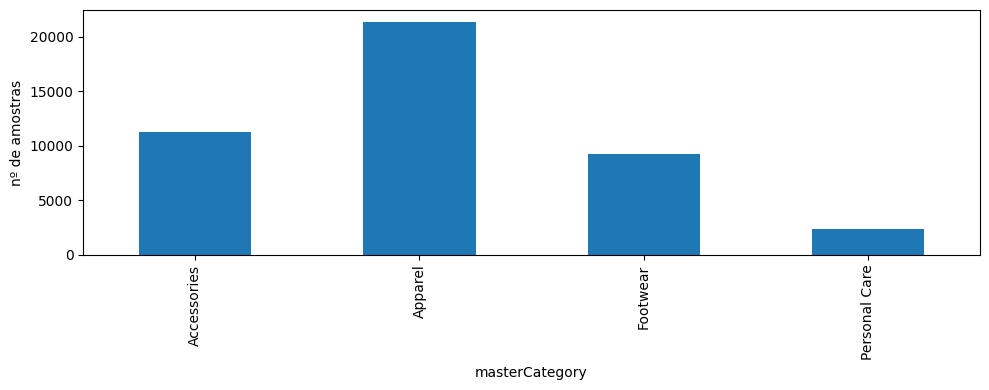

In [13]:
# Gráfico da distribuição final das classes
df[TARGET].value_counts().loc[classes].plot(kind="bar", figsize=(10, 4))
plt.ylabel("nº de amostras")
plt.tight_layout()
plt.show()

## 4. Pré-processamento das imagens

In [14]:
IMG_W, IMG_H = 40, 30  # tamanho final da imagem

def load_image(path):
    # Abre, converte para RGB e redimensiona
    img = Image.open(path).convert("RGB").resize((IMG_W, IMG_H))
    # Normaliza para [0, 1] e achata em vetor
    return np.asarray(img, dtype=np.float32).reshape(-1) / 255.0

In [15]:
# Lê todas as imagens e monta a matriz de entrada
X = np.stack([load_image(p) for p in df["image_path"]])
y = df["label"].values
print("X:", X.shape, "| y:", y.shape)

X: (44288, 3600) | y: (44288,)


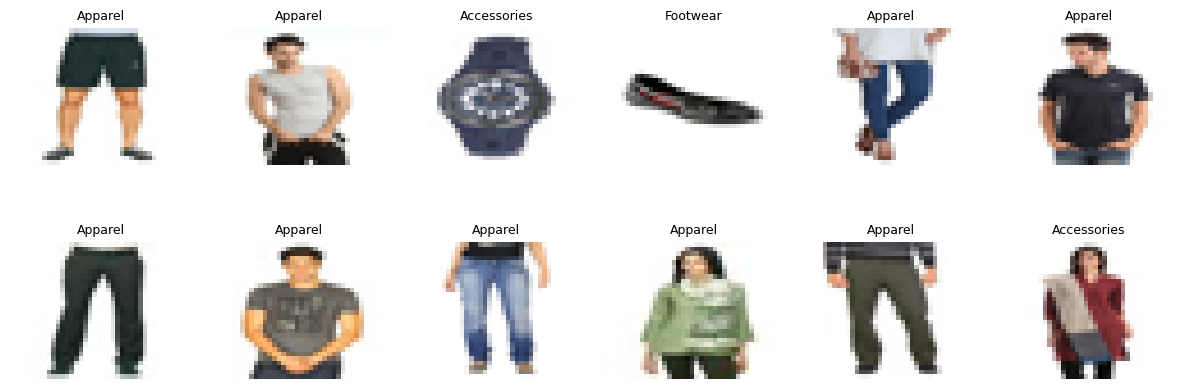

In [16]:
# Mostra 12 exemplos aleatórios
fig, axes = plt.subplots(2, 6, figsize=(12, 5))
for ax, idx in zip(axes.ravel(), np.random.choice(len(df), 12, replace=False)):
    ax.imshow(X[idx].reshape(IMG_H, IMG_W, 3))
    ax.set_title(classes[y[idx]], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Divisão treino / validação / teste

In [17]:
# 85% para treino+validação e 15% para teste (estratificado)
X_trv, X_test, y_trv, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED
)

# Separa a validação (~15% do total)
X_train, X_val, y_train, y_val = train_test_split(
    X_trv, y_trv, test_size=0.1765, stratify=y_trv, random_state=SEED
)
print(f"Treino: {len(X_train)} | Validação: {len(X_val)} | Teste: {len(X_test)}")

Treino: 30999 | Validação: 6645 | Teste: 6644


In [18]:
# Tamanho dos lotes (batches)
BATCH_SIZE = 128

def make_loader(X_, y_, shuffle):
    # Transforma arrays em tensores e cria o DataLoader
    ds = TensorDataset(torch.tensor(X_), torch.tensor(y_, dtype=torch.long))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)

train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader = make_loader(X_val, y_val, shuffle=False)
test_loader = make_loader(X_test, y_test, shuffle=False)

In [19]:
# Linha de base: acurácia de sempre prever a classe mais comum
majority = np.bincount(y_train).argmax()
baseline_acc = (y_test == majority).mean()
print(f"Baseline: {baseline_acc:.2%}")

Baseline: 48.30%


## 6. Definição do modelo

In [20]:
class MLP(nn.Module):
    # Rede densa: camadas lineares + ReLU + Dropout
    def __init__(self, n_in, n_out, hidden=(512, 256), p_drop=0.3):
        super().__init__()
        layers, prev = [], n_in
        for h_size in hidden:
            layers += [nn.Linear(prev, h_size), nn.ReLU(), nn.Dropout(p_drop)]
            prev = h_size
        layers.append(nn.Linear(prev, n_out))  # saída: logits
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

In [21]:
# Instancia o modelo e mostra o número de parâmetros
model = MLP(X.shape[1], len(classes)).to(device)
print(model)
print("Parâmetros:", sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Linear(in_features=3600, out_features=512, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=256, out_features=4, bias=True)
  )
)
Parâmetros: 1976068


## 7. Treinamento

In [22]:
# Hiperparâmetros do treino
EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 5  # épocas sem melhora antes de parar

os.makedirs("./data/models", exist_ok=True)
MODEL_PATH = "./data/models/mlp_fashion_best.pt"

# Função de custo e otimizador
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

In [23]:
def run_epoch(loader, train):
    # Roda uma época: treina (train=True) ou só avalia (train=False)
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad()   # zera gradientes
                loss.backward()         # calcula gradientes
                optimizer.step()        # atualiza pesos
            total_loss += loss.item() * len(yb)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n

In [24]:
# Loop de treinamento com early stopping
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
best_val_loss, bad_epochs = float("inf"), 0

for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = run_epoch(train_loader, train=True)
    va_loss, va_acc = run_epoch(val_loader, train=False)

    # Guarda o histórico
    history["train_loss"].append(tr_loss)
    history["val_loss"].append(va_loss)
    history["train_acc"].append(tr_acc)
    history["val_acc"].append(va_acc)

    print(f"época {epoch:02d} | treino {tr_acc:.2%} / custo {tr_loss:.4f} "
          f"| validação {va_acc:.2%} / custo {va_loss:.4f}")

    # Salva o melhor modelo pelo custo de validação
    if va_loss < best_val_loss:
        best_val_loss, bad_epochs = va_loss, 0
        torch.save(model.state_dict(), MODEL_PATH)
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print("Early stopping.")
            break

# Recarrega os melhores pesos
model.load_state_dict(torch.load(MODEL_PATH, map_location=device))

época 01 | treino 81.63% / custo 0.4762 | validação 91.17% / custo 0.2873
época 02 | treino 88.60% / custo 0.3161 | validação 90.10% / custo 0.2742
época 03 | treino 88.38% / custo 0.3210 | validação 90.67% / custo 0.2774
época 04 | treino 88.05% / custo 0.3192 | validação 89.24% / custo 0.2936
época 05 | treino 88.55% / custo 0.3106 | validação 90.13% / custo 0.2799
época 06 | treino 88.85% / custo 0.3021 | validação 91.12% / custo 0.2572
época 07 | treino 88.93% / custo 0.2969 | validação 90.01% / custo 0.2625
época 08 | treino 88.38% / custo 0.3035 | validação 93.02% / custo 0.2419
época 09 | treino 88.29% / custo 0.3044 | validação 93.72% / custo 0.2069
época 10 | treino 89.23% / custo 0.2869 | validação 93.06% / custo 0.2133
época 11 | treino 90.02% / custo 0.2714 | validação 93.89% / custo 0.1954
época 12 | treino 89.92% / custo 0.2747 | validação 92.46% / custo 0.2235
época 13 | treino 89.21% / custo 0.2926 | validação 93.53% / custo 0.2265
época 14 | treino 90.26% / custo 0.272

<All keys matched successfully>

## 8. Curvas de treino

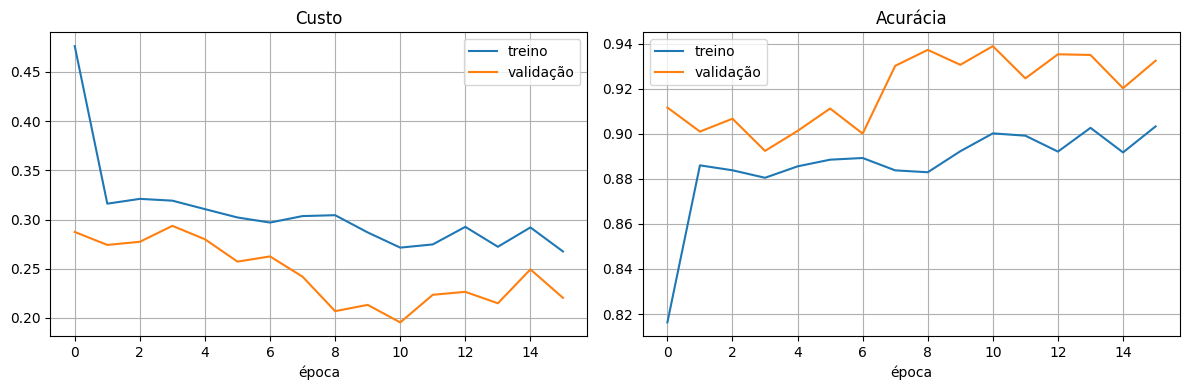

In [25]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Custo por época
ax1.plot(history["train_loss"], label="treino")
ax1.plot(history["val_loss"], label="validação")
ax1.set_title("Custo"); ax1.set_xlabel("época"); ax1.legend(); ax1.grid(True)

# Acurácia por época
ax2.plot(history["train_acc"], label="treino")
ax2.plot(history["val_acc"], label="validação")
ax2.set_title("Acurácia"); ax2.set_xlabel("época"); ax2.legend(); ax2.grid(True)

plt.tight_layout()
plt.show()

## 9. Avaliação no teste

In [26]:
# Métricas no conjunto de teste e no treino
test_loss, test_acc = run_epoch(test_loader, train=False)
_, train_acc_final = run_epoch(train_loader, train=False)

print(f"Acurácia no teste:  {test_acc:.2%}")
print(f"Custo no teste:     {test_loss:.4f}")
print(f"Acurácia no treino: {train_acc_final:.2%}")
print(f"Baseline:           {baseline_acc:.2%}")
print("Critério ACC:", "≥ 70% → 4 pontos" if test_acc >= 0.70 else "< 70% → 2 pontos")

Acurácia no teste:  93.86%
Custo no teste:     0.1926
Acurácia no treino: 94.08%
Baseline:           48.30%
Critério ACC: ≥ 70% → 4 pontos


In [27]:
# Predições do modelo no teste
model.eval()
with torch.no_grad():
    logits = model(torch.tensor(X_test).to(device))
y_pred = logits.argmax(dim=1).cpu().numpy()

## 10. Matriz de confusão e métricas por classe

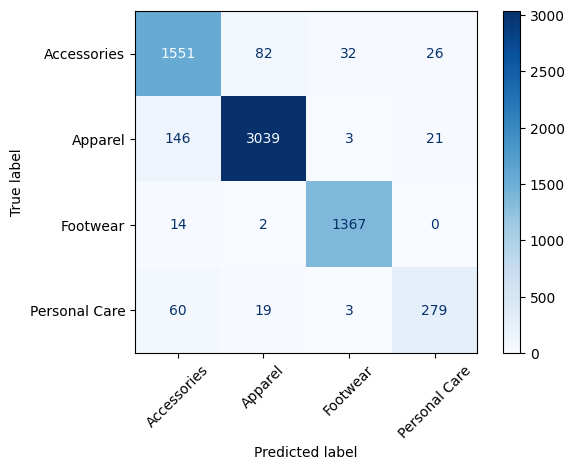

In [28]:
# Matriz de confusão
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=classes).plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()

In [29]:
# Precisão, recall e F1 por classe
print(classification_report(y_test, y_pred, target_names=classes, digits=3))

               precision    recall  f1-score   support

  Accessories      0.876     0.917     0.896      1691
      Apparel      0.967     0.947     0.957      3209
     Footwear      0.973     0.988     0.981      1383
Personal Care      0.856     0.773     0.812       361

     accuracy                          0.939      6644
    macro avg      0.918     0.906     0.911      6644
 weighted avg      0.939     0.939     0.939      6644



## 11. Overfitting ou underfitting

In [31]:
# Diferença entre treino e validação na melhor época
best_idx = int(np.argmin(history["val_loss"]))
val_acc_best = history["val_acc"][best_idx]
gap = train_acc_final - val_acc_best

print(f"Treino: {train_acc_final:.2%} | Validação: {val_acc_best:.2%} | Diferença: {gap:.2%}")
if gap > 0.05:
    print("Sinal de overfitting.")
elif val_acc_best < 0.7:
    print("Sinal de underfitting.")
else:
    print("Treino e validação equilibrados.")

Treino: 94.08% | Validação: 93.89% | Diferença: 0.19%
Treino e validação equilibrados.
